In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import (
    FuncFormatter, PercentFormatter)
from matplotlib.patches import Patch
from google.colab import drive

In [2]:
drive.mount("/content/drive")
P = "/content/drive/MyDrive/Phase5/"
P += "scms_clean.csv"
df = pd.read_csv(
    P, parse_dates=["sched", "deliv"])
assert len(df) == 10324
assert round(1 - df["late"].mean(), 3) == 0.885

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
s = df[~df["is_rdc"]]
g = s.groupby("Vendor")
t = pd.DataFrame({
    "lines": g.size(),
    "late_rate": g["late"].mean(),
    "spend": g["value"].sum()})
L = s[s["late"]]
lg = L.groupby("Vendor")
t["risk"] = lg["value"].sum()
t["risk"] = t["risk"].fillna(0)
t["risk_share"] = t["risk"] / t["spend"]
t["med_late"] = lg["days_late"].median()
t["late_lines"] = lg.size().reindex(t.index).fillna(0).astype(int)
t["mean_late"] = lg["days_late"].mean()
t = t[t["lines"] >= 20]
assert len(t) == 24
top = t.sort_values(
    "late_rate", ascending=False)
print(top.head(10).round(3))
# spot check one vendor by hand
v = top.index[0]
x = s[s["Vendor"] == v]
print(v, len(x), (x["days_late"] > 0).mean())

                                              lines  late_rate         spend  \
Vendor                                                                         
BIO-RAD LABORATORIES (FRANCE)                    28      0.143  1.493378e+06   
Aurobindo Pharma Limited                        668      0.141  9.138371e+07   
CIPLA LIMITED                                   175      0.131  3.965869e+07   
Orgenics, Ltd                                   754      0.130  1.477034e+08   
EMCURE PHARMACEUTICALS LTD                       41      0.049  5.756840e+06   
Abbott GmbH & Co. KG                             21      0.048  2.342400e+06   
STRIDES ARCOLAB LIMITED                          93      0.043  2.248547e+07   
Standard Diagnostics, Inc.                       98      0.041  8.887046e+06   
SHANGHAI KEHUA BIOENGINEERING CO.,LTD. (KHB)     70      0.029  7.325764e+06   
JSI R&T INSTITUTE, INC.                          38      0.026  2.506896e+05   

                                       

In [4]:
print(df.groupby("is_rdc")["late"]
        .agg(["size", "mean"]))
La = df[df["late"]]
print(La["days_late"].median(),
      La["days_late"].mean())
print(La["value"].sum(),
      df["value"].sum())
print(df.groupby("Shipment Mode")["late"]
        .agg(["size", "mean"]))

        size      mean
is_rdc                
False   4920  0.052642
True    5404  0.171540
12.0 21.36930860033727
259034270.94 1627584457.29
               size      mean
Shipment Mode                
Air            6113  0.096025
Air Charter     650  0.115385
Ocean           371  0.175202
Truck          2830  0.160777


In [5]:
x = df[df["days_late"] >= -90]
print(len(x), 1 - x["late"].mean())

10100 0.8825742574257426


In [6]:
r = t["risk"].sort_values(ascending=False)
print(r.head(5))
print(r.head(5).sum() / r.sum())

Lt = L[L["Vendor"].isin(t.index)]
big = Lt.nlargest(5, "value")
print(big[["Vendor", "value", "days_late"]])
print(big["value"].sum() / Lt["value"].sum())
print(round(Lt["value"].sum()), round(r.sum()))


Vendor
Orgenics, Ltd                 26086043.78
Aurobindo Pharma Limited      18656561.21
CIPLA LIMITED                  6398239.83
STRIDES ARCOLAB LIMITED        1210625.44
Standard Diagnostics, Inc.      800000.00
Name: risk, dtype: float64
0.9434864962049082
                        Vendor       value  days_late
5903  Aurobindo Pharma Limited  1048441.38         13
5363  Aurobindo Pharma Limited   975355.50         71
5420             Orgenics, Ltd   922396.00          1
4750  Aurobindo Pharma Limited   826674.80          7
3125             Orgenics, Ltd   741459.00          2
0.08013336679498913
56335168 56335168


In [7]:
# Insights built from variables only; the three biggest suppliers use the same 24-supplier table t
d = df.groupby("is_rdc")["late"].agg(["size", "mean"])
print(f"Insight 1: RDC lines were late {d.loc[True,'mean']:.1%} of the time ({d.loc[True,'size']:,} lines) "
      f"against {d.loc[False,'mean']:.1%} for direct drop ({d.loc[False,'size']:,} lines), "
      f"{d.loc[True,'mean']/d.loc[False,'mean']:.1f}x higher. Check RDC routing first. "
      f"The data shows where the lateness sits, not why.")

big3 = ["Orgenics, Ltd", "Aurobindo Pharma Limited", "CIPLA LIMITED"]
sp_share = t.loc[big3, "spend"].sum() / t["spend"].sum()
rk_share = t.loc[big3, "risk"].sum() / t["risk"].sum()
Lt = L[L["Vendor"].isin(t.index)]
big5 = Lt.nlargest(5, "value")["value"].sum() / Lt["value"].sum()
print(f"Insight 2: Orgenics, Aurobindo and Cipla hold {sp_share:.1%} of supplier spend but {rk_share:.1%} "
      f"of the ${t['risk'].sum()/1e6:.1f}M spend at risk. No few giant lines drive it: the five biggest "
      f"late lines are only {big5:.1%} of it. Review these three first.")

o, a, c = (t.loc[n] for n in big3)
print(f"Insight 3: the three are late at similar rates ({o['late_rate']:.1%} to {a['late_rate']:.1%}), "
      f"but the median delay is {o['med_late']:.0f} days for Orgenics ({o['late_lines']:.0f} late lines), "
      f"{a['med_late']:.0f} for Aurobindo ({a['late_lines']:.0f}) and {c['med_late']:.0f} for Cipla "
      f"({c['late_lines']:.0f}). A 5-day slip and a month-long delay call for different questions to each supplier. "
      f"Cipla's median rests on only {c['late_lines']:.0f} lines.")

Insight 1: RDC lines were late 17.2% of the time (5,404 lines) against 5.3% for direct drop (4,920 lines), 3.3x higher. Check RDC routing first. The data shows where the lateness sits, not why.
Insight 2: Orgenics, Aurobindo and Cipla hold 52.2% of supplier spend but 90.8% of the $56.3M spend at risk. No few giant lines drive it: the five biggest late lines are only 8.0% of it. Review these three first.
Insight 3: the three are late at similar rates (13.0% to 14.1%), but the median delay is 5 days for Orgenics (98 late lines), 27 for Aurobindo (94) and 33 for Cipla (23). A 5-day slip and a month-long delay call for different questions to each supplier. Cipla's median rests on only 23 lines.


In [8]:
OUT = "/content/drive/MyDrive/Phase5/"

def style():
    plt.rcParams.update({
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "figure.dpi": 100})
style()

def short(n):
    n = (n.title().replace(" Laboratories", " Labs").replace("Gmbh", "GmbH")
          .replace(" Kg", " KG").replace("Jsi", "JSI"))
    return n if len(n) <= 26 else n[:24] + "..."

big3 = ["Orgenics, Ltd",
        "Aurobindo Pharma Limited",
        "CIPLA LIMITED"]
RED, GREY = "#c0392b", "#9aa5b1"

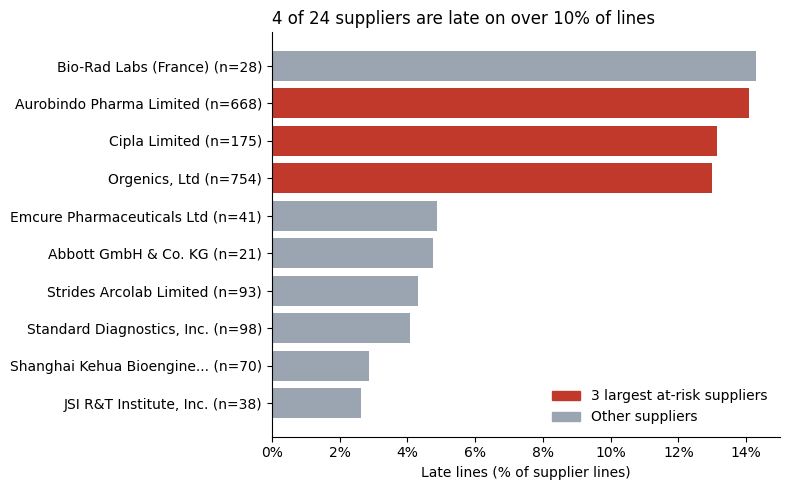

4


In [9]:
top = t.sort_values(
    "late_rate", ascending=False)
d = top.head(10).iloc[::-1]
labels = [f"{short(v)} (n={n})"
          for v, n in zip(d.index, d["lines"])]
colors = [RED if v in big3 else GREY
          for v in d.index]
cut = 0.10
k = (top["late_rate"] > cut).sum()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels, d["late_rate"], color=colors)
ax.xaxis.set_major_formatter(
    PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Late lines (% of supplier lines)")
ax.set_title(
    f"{k} of {len(t)} suppliers are late "
    f"on over {cut:.0%} of lines", loc="left")
ax.legend(handles=[
    Patch(color=RED,
          label=f"{len(big3)} largest at-risk suppliers"),
    Patch(color=GREY, label="Other suppliers")],
    loc="lower right", frameon=False)
plt.tight_layout()
fig.savefig(OUT + "chart1_late_rate.png",
            dpi=150)
plt.show()
print(k)

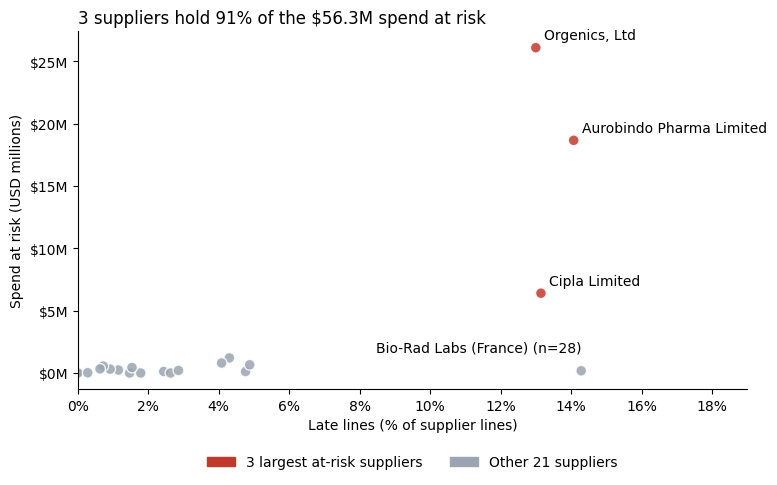

0.908 56.3


In [10]:
tot = t["risk"].sum()
sh = t.loc[big3, "risk"].sum() / tot
cs = [RED if v in big3 else GREY
      for v in t.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(t["late_rate"], t["risk"],
           s=60, c=cs, alpha=0.85, edgecolor="white")
for v in big3:
    ax.annotate(
        short(v),
        (t.loc[v, "late_rate"],
         t.loc[v, "risk"]),
        xytext=(6, 6),
        textcoords="offset points")
bv = t["late_rate"].idxmax()
ax.annotate(f"{short(bv)} (n={t.loc[bv, 'lines']})",
            (t.loc[bv, "late_rate"], t.loc[bv, "risk"]),
            xytext=(0, 14), textcoords="offset points", ha="right")
ax.set_xlim(0, 0.19)
ax.set_xticks(np.arange(0, 0.19, 0.02))
ax.xaxis.set_major_formatter(
    PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1e6:.0f}M"))
ax.set_xlabel("Late lines (% of supplier lines)")
ax.set_ylabel("Spend at risk (USD millions)")
ax.set_title(
    f"{len(big3)} suppliers hold {sh:.0%} "
    f"of the ${tot/1e6:.1f}M spend at risk",
    loc="left")
ax.legend(handles=[
    Patch(color=RED, label=f"{len(big3)} largest at-risk suppliers"),
    Patch(color=GREY, label=f"Other {len(t) - len(big3)} suppliers")],
    loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
fig.savefig(OUT + "chart2_spend_risk.png", dpi=150, bbox_inches="tight")
plt.show()
print(round(sh, 3), round(tot / 1e6, 1))

In [14]:
MINL = 20
rd = df.groupby("is_rdc")["late"].mean()
rdc, drop = rd.loc[True], rd.loc[False]
b = t.loc[big3]
ot = 1 - df["late"].mean()
y0 = df["sched"].dt.year.min()
y1 = df["sched"].dt.year.max()
names = ", ".join(
    short(v).split(",")[0].replace(" Limited", "")
    for v in big3)

problem = (
    f"Which suppliers deliver late most often, "
    f"and how much spend is exposed? "
    f"{len(df):,} line items, {y0} to {y1}, "
    f"{len(t)} suppliers with {MINL}+ lines.")
method = (
    f"I cleaned the data in pandas, set aside the "
    f"{df['is_rdc'].sum():,} RDC lines, and measured "
    f"late rate, days late and spend at risk "
    f"(value of late lines) per supplier.")
insight = (
    f"{names} hold {sh:.0%} of the "
    f"${tot/1e6:.1f}M spend at risk. Their late "
    f"rates are similar ({b['late_rate'].min():.1%}"
    f" to {b['late_rate'].max():.1%}) but their "
    f"median delays run from "
    f"{b['med_late'].min():.0f} to "
    f"{b['med_late'].max():.0f} days. RDC lines "
    f"are late {rdc:.1%} of the time against "
    f"{drop:.1%} for direct drop.")
limit = (
    f"Limit: the median gap between scheduled and "
    f"delivered is {df['days_late'].median():.0f} "
    f"days, so scheduled dates may have been "
    f"revised and the {ot:.1%} on-time rate may "
    f"flatter suppliers.")
x = df[df["days_late"] >= -90]
check = (
    f"Without the {(df['days_late'] < -90).sum()} "
    f"lines more than 90 days early, on-time is "
    f"{1 - x['late'].mean():.1%} instead of {ot:.1%}.")

In [12]:
by_risk = b.sort_values("risk", ascending=False)
rec = (f"Review {', '.join(short(v) for v in by_risk.index)} first, since together they hold "
       f"{sh:.0%} of the spend at risk. Ask each why {b['late_rate'].min():.1%} to "
       f"{b['late_rate'].max():.1%} of their lines arrive late, and whether the median delay of "
       f"{b['med_late'].min():.0f} to {b['med_late'].max():.0f} days is a scheduling or a delivery problem.")

In [15]:
print("\n\n".join(
    [problem, method, insight, rec, limit]))
print(check)

Which suppliers deliver late most often, and how much spend is exposed? 10,324 line items, 2006 to 2015, 24 suppliers with 20+ lines.

I cleaned the data in pandas, set aside the 5,404 RDC lines, and measured late rate, days late and spend at risk (value of late lines) per supplier.

Orgenics, Aurobindo Pharma, Cipla hold 91% of the $56.3M spend at risk. Their late rates are similar (13.0% to 14.1%) but their median delays run from 5 to 33 days. RDC lines are late 17.2% of the time against 5.3% for direct drop.

Review Orgenics, Ltd, Aurobindo Pharma Limited, Cipla Limited first, since together they hold 91% of the spend at risk. Ask each why 13.0% to 14.1% of their lines arrive late, and whether the median delay of 5 to 33 days is a scheduling or a delivery problem.

Limit: the median gap between scheduled and delivered is 0 days, so scheduled dates may have been revised and the 88.5% on-time rate may flatter suppliers.
Without the 224 lines more than 90 days early, on-time is 88.3% i